# **Assignment 4**
## **Build Your Own Segmentation Model**

> **MISSION LOG - Day 4**
>
> Mary can now name what her cameras see. But a name is not enough: to fly through an asteroid field she has to know *where* every object is, pixel by pixel. No repair manual this time. Nobody hands you the model. **You build it**, starting from the pretrained backbone you used in Assignment 3, and prove that it works on a hidden exam.

### **How this notebook works**

1) **Save your own copy:** *File -> Save a copy in Drive*. Turn on a GPU: *Runtime -> Change runtime type -> T4 GPU*.
2) There are only **four kinds of cells** here, and you must understand which are yours:
   - **DO NOT EDIT cells** (imports, dataset download, the checker). Leave them exactly as they are. You may *add* your own imports in your own cells.
   - **The Question Sheet** (a markdown cell). Every time you work out a number, come back here and write it down. This will be evaluated.
   - **YOUR WORK** area. Everything you build goes here. Copy as much as you like from your Assignment 3 notebook. Add as many cells as you want.
   - **The final evaluation cell** at the bottom. Whether you pass depends on its result.
3) Read the PDF first. It contains the dataset details, the *contract* your model must follow, and the detailed steps.
4) Run cells from top to bottom.

In [ ]:
# ===================== DO NOT EDIT THIS CELL =====================
# You may add more imports in your OWN cells below, but do not remove these.
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
import torchvision.transforms.functional as TF

In [ ]:
# ===================== DO NOT EDIT THIS CELL =====================
# Downloads the Oxford-IIIT Pet dataset (official 'trainval' split) with segmentation masks.
# Images and masks come back as raw PIL images of DIFFERENT sizes. Preprocessing is YOUR job.
# The hidden test split is loaded separately by the checker. Never train on it.
trainval_raw = datasets.OxfordIIITPet(root="./data", split="trainval", target_types="segmentation", download=True)
print("Images in trainval:", len(trainval_raw))
img, mask = trainval_raw[0]
print("Example image:", img.size, img.mode, "| example mask:", mask.size, mask.mode)

Images in trainval: 3680
Example image: (394, 500) RGB | example mask: (394, 500) L


---
## **QUESTION SHEET**
Fill in each answer **as soon as you work it out** (double-click this cell, replace the `____`). Where it says *predict first*, write your prediction **before** you measure it. Write numbers with enough digits (e.g. 0.6667, not "about 0.7").

### A. The raw data
**A1.** Unique values found in a raw mask (before any change): __1, 2, 3__

**A2.** Size (width x height) of `trainval_raw[0]`'s image: __394 × 500__

**A3.** Do all images share one size? (yes/no): __No__

**A4.** Number of images in `trainval_raw`: __3680__

### B. Your split (see the PDF, Step 4)
**B1.** Number of training images: __2944__

**B2.** Number of validation images: __736__

**B3.** Your batch size: __16__   Number of batches in one training epoch: __184__

### C. Class balance and the baseline (training images, after resizing to 128x128 and remapping labels)
**C1.** Fraction of pixels that are *pet*: __0.3001__

**C2.** Fraction of pixels that are *background*: __0.5863__

**C3.** Fraction of pixels that are *border*: __0.1136__

**C4.** *Predict first:* accuracy of a model that says "background" for every pixel: __0.5863__

**C5.** Accuracy of that model measured by the checker (test set): __0.5772__   mean IoU of that model: __0.1924__

### D. Metrics by hand (use the 4x4 pair printed in the PDF, Appendix)
**D1.** IoU of the *pet* class: __TP / (TP + FP + FN)__

**D2.** Dice of the *pet* class: __2TP / (2TP + FP + FN)__

**D3.** Pixel accuracy (all 16 pixels): __(TP + TN) / 16__

**D4.** IoU of the *not-pet* class: __TN / (TN + FP + FN)__

### E. Shapes (input batch of 16 images of 128x128; do it on paper BEFORE you print the real shapes)
**E1.** Which ResNet did you use (18 or 34)? __ResNet-18__

**E2.** Feature map shape (channels, height, width) of one image after `layer1`: __(64, 32, 32)__

**E3.** ... after `layer2`: __(128, 16, 16)__

**E4.** ... after `layer3`: __(256, 8, 8)__

**E5.** ... after `layer4`: __(512, 4, 4)__

**E6.** How many times must you upsample by 2 to get from the `layer4` map back to 128x128? __5__

**E7.** Number of skip connections in your decoder: __4__

**E8.** Input channels of your first decoder convolution (after concatenating the skip): __768__

**E9.** Output shape of your whole model for a batch of 16 images: __(16, 3, 128, 128)__

### F. Sanity checks
**F1.** *Predict first:* loss of an untrained 3-class model on one batch (cross-entropy, all classes equally likely): __1.0986__

**F2.** Loss your model really gave on its first batch: __1.1443__

**F3.** Overfit-one-batch test: batch size __4__, steps taken __200__, final loss __0.028328__

### G. Training
**G1.** Loss function: __Cross-Entropy + Dice Loss__   Optimizer: __Adam__   Learning rate(s): __0.0001(Encoder), 0.001(Decoder)__   Epochs: __15__

**G2.** Seconds per epoch: __19.21 seconds__

**G3.** Best validation epoch: __15__   Train loss there: __0.2711__   Validation loss there: __0.3916__   Validation mean IoU there: __0.7780__

### H. Final results (from the checker)
**H1.** Test mean IoU: __0.7822__

**H2.** IoU pet: __0.8593__   IoU background: __0.9273__   IoU border: __0.5599__

**H3.** Which class has the lowest IoU? __Border__

### I. Your one-variable experiment
**I1.** The one thing you changed (frozen vs fine-tuned encoder / with vs without skips / CE vs Dice loss / other): __Cross-Entropy Loss vs Cross-Entropy + Dice Loss__

**I2.** *Predict first:* change in validation mean IoU: __+0.0200__

**I3.** Actual change in validation mean IoU: __+0.0034__
---

## **The checker**  (run it once now, so `evaluate` exists later)
It loads the hidden test set, runs your model on it and reports the official result. It can only be *called*, not changed. The contract your model must obey is in the PDF.

In [ ]:
# ===================== DO NOT EDIT THIS CELL =====================
# This is the official checker. Editing it will make your result invalid.
from PIL import Image

PASS_MIOU = 0.65          # minimum mean IoU on the hidden test set to pass
DISTINCTION_MIOU = 0.75   # mean IoU needed for a distinction
_CLASS_NAMES = ["pet", "background", "border"]
_IMG = 128
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
_TEST = {}

def _load_test_set():
    """Loads the official TEST split once, resized to 128x128, labels 0=pet 1=background 2=border."""
    if "x" in _TEST:
        return
    print("Loading the hidden test set (first call only, takes a minute)...")
    ds = datasets.OxfordIIITPet(root="./data", split="test", target_types="segmentation", download=True)
    xs, ys = [], []
    for img, mask in ds:
        img = img.convert("RGB").resize((_IMG, _IMG), Image.BILINEAR)
        mask = mask.resize((_IMG, _IMG), Image.NEAREST)          # nearest: never invent new labels
        xs.append(np.asarray(img, dtype=np.uint8))
        ys.append(np.asarray(mask, dtype=np.int16) - 1)           # raw 1,2,3 -> 0,1,2
    _TEST["x"] = np.stack(xs)
    _TEST["y"] = np.stack(ys).astype(np.int64)
    bad = np.setdiff1d(np.unique(_TEST["y"]), [0, 1, 2])
    if len(bad) > 0:
        raise RuntimeError(f"Checker problem: unexpected mask values {bad}. Tell your instructor.")

def _scores(conf):
    tp = np.diag(conf).astype(float)
    rows, cols = conf.sum(1).astype(float), conf.sum(0).astype(float)
    iou = np.where(rows + cols - tp > 0, tp / np.maximum(rows + cols - tp, 1), np.nan)
    dice = np.where(rows + cols > 0, 2 * tp / np.maximum(rows + cols, 1), np.nan)
    return iou, dice

def evaluate(model, batch_size=64, show_failures=True):
    """Official evaluation. Call it as evaluate(model). Your model must follow the contract in the PDF."""
    _load_test_set()
    X, Y = _TEST["x"], _TEST["y"]
    dev = next(model.parameters()).device
    was_training = model.training
    model.eval()
    t0 = time.time()
    conf = np.zeros((3, 3), dtype=np.int64)
    per_image, preds = [], []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = torch.from_numpy(X[i:i + batch_size]).permute(0, 3, 1, 2).float() / 255.0
            xb = ((xb - _MEAN) / _STD).to(dev)
            out = model(xb)
            if not (torch.is_tensor(out) and tuple(out.shape) == (xb.shape[0], 3, _IMG, _IMG)):
                shp = tuple(out.shape) if torch.is_tensor(out) else type(out)
                raise ValueError(f"SHAPE CHECK FAILED: for input {tuple(xb.shape)} your model must return "
                                 f"{(xb.shape[0], 3, _IMG, _IMG)} (raw scores), but returned {shp}.")
            p = out.argmax(1).cpu().numpy()
            y = Y[i:i + batch_size]
            n = len(y)
            idx = (np.arange(n)[:, None, None] * 9 + y * 3 + p).ravel()
            c = np.bincount(idx, minlength=n * 9).reshape(n, 3, 3)
            conf += c.sum(0)
            for k in range(n):
                per_image.append(np.nanmean(_scores(c[k])[0]))
            preds.append(p.astype(np.uint8))
    if was_training:
        model.train()
    preds = np.concatenate(preds)
    per_image = np.array(per_image)
    iou, dice = _scores(conf)
    miou, mdice = float(np.nanmean(iou)), float(np.nanmean(dice))
    acc = float(np.diag(conf).sum() / conf.sum())
    # baseline: predict "background" for every pixel
    base_conf = np.zeros((3, 3), dtype=np.int64)
    base_conf[:, 1] = conf.sum(1)
    base_iou, _ = _scores(base_conf)
    base_miou, base_acc = float(np.nanmean(np.nan_to_num(base_iou))), float(base_conf[1, 1] / base_conf.sum())

    print("=" * 60)
    print(f"OFFICIAL RESULT on {len(X)} test images   ({time.time() - t0:.0f}s)")
    print("=" * 60)
    print(f"{'':14}{'your model':>14}{'all-background':>18}")
    print(f"{'pixel accuracy':14}{acc:>14.4f}{base_acc:>18.4f}")
    print(f"{'mean IoU':14}{miou:>14.4f}{base_miou:>18.4f}")
    print(f"{'mean Dice':14}{mdice:>14.4f}")
    for n_, v in zip(_CLASS_NAMES, iou):
        print(f"  IoU {n_:<12}{v:>10.4f}")
    for n_, v in zip(_CLASS_NAMES, dice):
        print(f"  Dice {n_:<11}{v:>10.4f}")
    print("-" * 60)
    print("Shape check : PASSED")
    beats = miou > base_miou
    print(f"Beats the all-background baseline : {'PASSED' if beats else 'FAILED'}")
    ok = miou >= PASS_MIOU
    print(f"mIoU >= {PASS_MIOU:.2f} : {'PASSED' if ok else 'FAILED'}")
    if ok and beats:
        print("VERDICT: PASS" + ("  (DISTINCTION!)" if miou >= DISTINCTION_MIOU else ""))
    else:
        print("VERDICT: NOT YET. Look at the failures below and keep iterating.")
    print("=" * 60)

    if show_failures:
        worst = np.argsort(per_image)[:8]
        fig, axes = plt.subplots(4, 6, figsize=(15, 10))
        for ax in axes.flat:
            ax.axis("off")
        for j, w in enumerate(worst):
            r, c0 = j // 2, (j % 2) * 3
            axes[r, c0].imshow(X[w]);                            axes[r, c0].set_title(f"image {w}  IoU {per_image[w]:.2f}", fontsize=9)
            axes[r, c0 + 1].imshow(Y[w], vmin=0, vmax=2, cmap="viridis");     axes[r, c0 + 1].set_title("truth", fontsize=9)
            axes[r, c0 + 2].imshow(preds[w], vmin=0, vmax=2, cmap="viridis"); axes[r, c0 + 2].set_title("your prediction", fontsize=9)
        plt.suptitle("The 8 hardest test images (colours: 0 pet, 1 background, 2 border)")
        plt.tight_layout(); plt.show()
    return {"miou": miou, "mdice": mdice, "accuracy": acc, "iou": dict(zip(_CLASS_NAMES, iou.tolist())),
            "baseline_miou": base_miou, "passed": bool(ok and beats)}


---
## **YOUR WORK STARTS HERE**
Build, step by step, following the PDF. Suggested order: inspect data, preprocessing, split, metrics, shapes on paper, model, sanity checks, training, evaluation, experiment, failure analysis. Add as many cells as you need. **Your final model must be stored in a variable called `model`.**

In [ ]:
# Your work goes in the cells below this one.

In [ ]:
# Setup

# Additional imports and configuration

import random
import copy
import math

from PIL import Image
from torchvision.transforms import InterpolationMode

SEED = 42
IMG_SIZE = 128
NUM_CLASSES = 3
BATCH_SIZE = 16
EPOCHS = 15

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

CLASS_NAMES = ["pet", "background", "border"]

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
# Inspect the raw data

# Inspect dataset properties

img, mask = trainval_raw[0]

print("A2. First image size:", img.size)
print("A4. Dataset size:", len(trainval_raw))

unique_values = set()
image_sizes = set()

for i in range(20):
    image_i, mask_i = trainval_raw[i]

    unique_values.update(np.unique(np.array(mask_i)))
    image_sizes.add(image_i.size)

print("A1. Unique mask values:", sorted(unique_values))
print("Number of different image sizes:", len(image_sizes))

print(
    "A3. All images share one size:",
    "Yes" if len(image_sizes) == 1 else "No"
)

A2. First image size: (394, 500)
A4. Dataset size: 3680
A1. Unique mask values: [np.uint8(1), np.uint8(2), np.uint8(3)]
Number of different image sizes: 19
A3. All images share one size: No


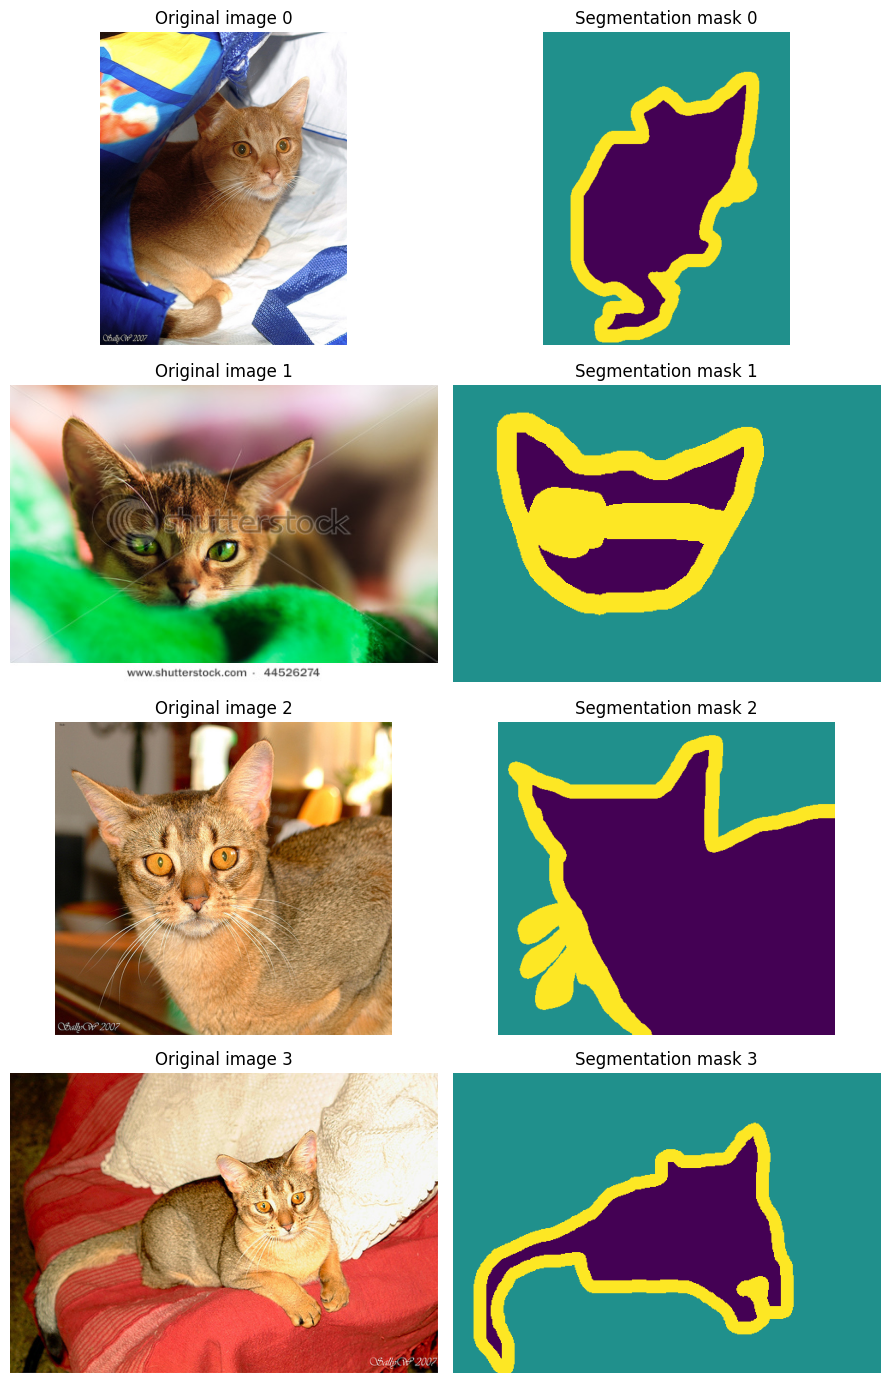

In [ ]:
# Visualize raw images and masks

fig, axes = plt.subplots(4, 2, figsize=(9, 14))

for i in range(4):
    img, mask = trainval_raw[i]

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Original image {i}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        np.array(mask),
        cmap="viridis",
        vmin=1,
        vmax=3
    )
    axes[i, 1].set_title(f"Segmentation mask {i}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Preprocessing

# Custom segmentation dataset

class PetSegmentationDataset(Dataset):

    def __init__(self, raw_dataset, indices, augment=False):
        self.raw_dataset = raw_dataset
        self.indices = indices
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        image, mask = self.raw_dataset[
            self.indices[idx]
        ]

        image = image.convert("RGB")

        # Resize image
        image = TF.resize(
            image,
            (IMG_SIZE, IMG_SIZE),
            interpolation=InterpolationMode.BILINEAR
        )

        # Resize segmentation mask
        mask = TF.resize(
            mask,
            (IMG_SIZE, IMG_SIZE),
            interpolation=InterpolationMode.NEAREST
        )

        # Apply identical augmentation
        if self.augment and random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        # Image: PIL -> float tensor
        image = TF.to_tensor(image)

        # ImageNet normalization
        image = TF.normalize(
            image,
            mean=MEAN,
            std=STD
        )

        # Mask: PIL -> long tensor
        mask = torch.from_numpy(
            np.array(mask, dtype=np.int64)
        ) - 1

        return image, mask

In [ ]:
# Verify preprocessing

preview_dataset = PetSegmentationDataset(
    trainval_raw,
    indices=list(range(5)),
    augment=False
)

image, mask = preview_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)

print("Unique labels:", torch.unique(mask))

assert image.shape == (3, 128, 128)
assert mask.shape == (128, 128)

assert mask.min() >= 0
assert mask.max() <= 2

Image shape: torch.Size([3, 128, 128])
Image dtype: torch.float32
Mask shape: torch.Size([128, 128])
Mask dtype: torch.int64
Unique labels: tensor([0, 1, 2])


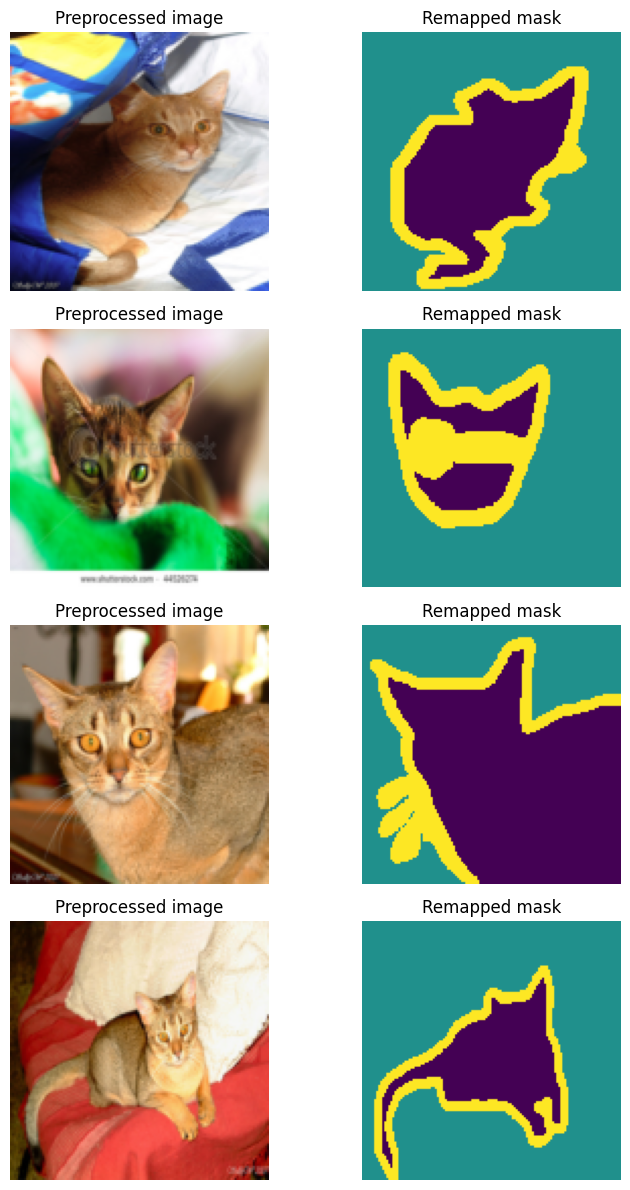

In [ ]:
# Visualize preprocessed samples

def denormalize(image):

    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)

    image = image.detach().cpu() * std + mean

    return image.clamp(0, 1).permute(1, 2, 0)


fig, axes = plt.subplots(4, 2, figsize=(8, 12))

for i in range(4):

    image, mask = preview_dataset[i]

    axes[i, 0].imshow(denormalize(image))
    axes[i, 0].set_title("Preprocessed image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        mask,
        cmap="viridis",
        vmin=0,
        vmax=2
    )
    axes[i, 1].set_title("Remapped mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Training and validation split

# Split dataset

generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    len(trainval_raw),
    generator=generator
).tolist()

train_size = int(0.8 * len(trainval_raw))

train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = PetSegmentationDataset(
    trainval_raw,
    train_indices,
    augment=True
)

val_dataset = PetSegmentationDataset(
    trainval_raw,
    val_indices,
    augment=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

assert len(
    set(train_indices) & set(val_indices)
) == 0

Training images: 2944
Validation images: 736


In [ ]:
# Create DataLoaders

def make_loaders(seed=42):

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
        generator=torch.Generator().manual_seed(seed)
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader


train_loader, val_loader = make_loaders(SEED)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)

Training batches: 184
Validation batches: 46
Batch size: 16


In [ ]:
# Check a batch

images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

Images: torch.Size([16, 3, 128, 128])
Masks: torch.Size([16, 128, 128])
Image dtype: torch.float32
Mask dtype: torch.int64


In [ ]:
# Class balance and baseline

# Pixel class distribution

class_counts = torch.zeros(
    NUM_CLASSES,
    dtype=torch.long
)

for idx in train_indices:

    _, mask = trainval_raw[idx]

    mask = TF.resize(
        mask,
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.NEAREST
    )

    mask = torch.from_numpy(
        np.array(mask, dtype=np.int64)
    ) - 1

    class_counts += torch.bincount(
        mask.flatten(),
        minlength=NUM_CLASSES
    )

total_pixels = class_counts.sum()

class_fractions = (
    class_counts.float() / total_pixels
)

for name, count, fraction in zip(
    CLASS_NAMES,
    class_counts,
    class_fractions
):
    print(
        f"{name:12s}: "
        f"Pixels={count.item():10d}, "
        f"Fraction={fraction.item():.4f}"
    )

print("Total pixels:", total_pixels.item())

pet         : Pixels=  14475187, Fraction=0.3001
background  : Pixels=  28281475, Fraction=0.5863
border      : Pixels=   5477834, Fraction=0.1136
Total pixels: 48234496


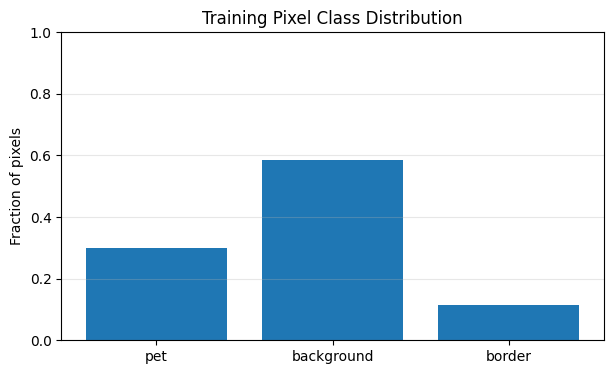

In [ ]:
# Plot class distribution

plt.figure(figsize=(7, 4))

plt.bar(
    CLASS_NAMES,
    class_fractions.numpy()
)

plt.ylabel("Fraction of pixels")
plt.title("Training Pixel Class Distribution")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# Predict all-background baseline

predicted_baseline_accuracy = class_fractions[1].item()

predicted_baseline_miou = (
    predicted_baseline_accuracy / 3
)

print(
    "C4. Predicted baseline accuracy:",
    f"{predicted_baseline_accuracy:.4f}"
)

print(
    "Estimated baseline mIoU:",
    f"{predicted_baseline_miou:.4f}"
)

C4. Predicted baseline accuracy: 0.5863
Estimated baseline mIoU: 0.1954


In [ ]:
# Segmentation metrics

# Mathematical definitions

# Confusion matrix function

def compute_confusion_matrix(
    predictions,
    targets,
    num_classes=3
):

    predictions = predictions.reshape(-1).long()
    targets = targets.reshape(-1).long()

    indices = targets * num_classes + predictions

    conf = torch.bincount(
        indices,
        minlength=num_classes ** 2
    )

    return conf.reshape(
        num_classes,
        num_classes
    )

In [ ]:
# IoU, Dice and accuracy

def segmentation_metrics(conf):

    conf = conf.double()

    tp = torch.diag(conf)

    actual = conf.sum(dim=1)
    predicted = conf.sum(dim=0)

    union = actual + predicted - tp

    iou = torch.where(
        union > 0,
        tp / union,
        float("nan")
    )

    dice = torch.where(
        actual + predicted > 0,
        2 * tp / (actual + predicted),
        float("nan")
    )

    accuracy = tp.sum() / conf.sum()

    return {
        "iou": iou.cpu().numpy(),
        "dice": dice.cpu().numpy(),
        "miou": torch.nanmean(iou).item(),
        "mdice": torch.nanmean(dice).item(),
        "accuracy": accuracy.item()
    }

In [ ]:
# Verify using the 4×4 Appendix example

# Enter the ground-truth matrix from the PDF
truth = torch.tensor([
    # [0, 1, 1, 0],
    # Enter remaining rows
])

# Enter the prediction matrix from the PDF
pred = torch.tensor([
    # Enter all four rows
])

if truth.shape == (4, 4) and pred.shape == (4, 4):

    conf_example = compute_confusion_matrix(
        pred,
        truth,
        num_classes=2
    )

    example_metrics = segmentation_metrics(
        conf_example
    )

    print("D1. Pet IoU:", example_metrics["iou"][1])

    print("D2. Pet Dice:", example_metrics["dice"][1])

    print("D3. Accuracy:", example_metrics["accuracy"])

    print("D4. Not-pet IoU:", example_metrics["iou"][0])

else:
    print("Enter both 4x4 matrices from the PDF.")

Enter both 4x4 matrices from the PDF.


In [ ]:
# Verify encoder shapes

# Encoder and decoder shapes

encoder = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
).to(device)

encoder.eval()

dummy = torch.zeros(
    16, 3, 128, 128
).to(device)

with torch.no_grad():

    x0 = encoder.relu(
        encoder.bn1(
            encoder.conv1(dummy)
        )
    )

    x1 = encoder.layer1(
        encoder.maxpool(x0)
    )

    x2 = encoder.layer2(x1)
    x3 = encoder.layer3(x2)
    x4 = encoder.layer4(x3)

print("Stem:", x0.shape)
print("Layer1:", x1.shape)
print("Layer2:", x2.shape)
print("Layer3:", x3.shape)
print("Layer4:", x4.shape)

del encoder, dummy, x0, x1, x2, x3, x4

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


Stem: torch.Size([16, 64, 64, 64])
Layer1: torch.Size([16, 64, 32, 32])
Layer2: torch.Size([16, 128, 16, 16])
Layer3: torch.Size([16, 256, 8, 8])
Layer4: torch.Size([16, 512, 4, 4])


In [ ]:
# Build your segmentation model

# Convolution block

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        return self.block(x)

In [ ]:
# Decoder block

class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):

        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip=None):

        if skip is not None:

            x = F.interpolate(
                x,
                size=skip.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            x = torch.cat(
                [x, skip],
                dim=1
            )

        else:

            x = F.interpolate(
                x,
                scale_factor=2,
                mode="bilinear",
                align_corners=False
            )

        return self.conv(x)

In [ ]:
# Complete ResNet-18 segmentation model

class ResNetUNet(nn.Module):

    def __init__(self, num_classes=3):

        super().__init__()

        resnet = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        # =====================
        # Encoder
        # =====================

        self.encoder = nn.ModuleDict({

            "stem": nn.Sequential(
                resnet.conv1,
                resnet.bn1,
                resnet.relu
            ),

            "maxpool": resnet.maxpool,

            "layer1": resnet.layer1,

            "layer2": resnet.layer2,

            "layer3": resnet.layer3,

            "layer4": resnet.layer4

        })

        # =====================
        # Decoder
        # =====================

        self.decoder1 = DecoderBlock(
            512, 256, 256
        )

        self.decoder2 = DecoderBlock(
            256, 128, 128
        )

        self.decoder3 = DecoderBlock(
            128, 64, 64
        )

        self.decoder4 = DecoderBlock(
            64, 64, 32
        )

        self.decoder5 = DecoderBlock(
            32, 0, 32
        )

        # Final segmentation head
        self.output_conv = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        x0 = self.encoder["stem"](x)

        x1 = self.encoder["layer1"](
            self.encoder["maxpool"](x0)
        )

        x2 = self.encoder["layer2"](x1)

        x3 = self.encoder["layer3"](x2)

        x4 = self.encoder["layer4"](x3)

        # Decoder with skip connections
        d1 = self.decoder1(x4, x3)

        d2 = self.decoder2(d1, x2)

        d3 = self.decoder3(d2, x1)

        d4 = self.decoder4(d3, x0)

        d5 = self.decoder5(d4)

        # Raw logits
        output = self.output_conv(d5)

        return output

In [ ]:
# Initialize model

set_seed(SEED)

model = ResNetUNet(
    num_classes=NUM_CLASSES
).to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

Total parameters: 14,339,747
Trainable parameters: 14,339,747


In [ ]:
# Sanity checks

# Shape verification

images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

model.eval()

with torch.no_grad():

    outputs = model(images)

print("Input shape:", images.shape)
print("Target shape:", masks.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (
    images.shape[0],
    3,
    128,
    128
)

print("Shape check: PASSED")

Input shape: torch.Size([16, 3, 128, 128])
Target shape: torch.Size([16, 128, 128])
Output shape: torch.Size([16, 3, 128, 128])
Shape check: PASSED


In [ ]:
# Initial loss prediction

# Measure actual initial loss

criterion = nn.CrossEntropyLoss()

print(
    "F1. Predicted initial loss:",
    f"{math.log(3):.4f}"
)

model.eval()

with torch.no_grad():

    outputs = model(images)

    initial_loss = criterion(
        outputs,
        masks
    ).item()

print(
    "F2. Actual initial loss:",
    f"{initial_loss:.4f}"
)

F1. Predicted initial loss: 1.0986
F2. Actual initial loss: 1.1443


In [ ]:
# Overfit one batch

sanity_model = copy.deepcopy(model)

sanity_model.train()

sanity_optimizer = optim.Adam(
    sanity_model.parameters(),
    lr=1e-3
)

SANITY_BATCH_SIZE = 4
SANITY_STEPS = 200

small_images, small_masks = next(iter(train_loader))

small_images = small_images[
    :SANITY_BATCH_SIZE
].to(device)

small_masks = small_masks[
    :SANITY_BATCH_SIZE
].to(device)

sanity_losses = []

for step in range(SANITY_STEPS):

    sanity_optimizer.zero_grad()

    outputs = sanity_model(small_images)

    loss = criterion(
        outputs,
        small_masks
    )

    loss.backward()

    sanity_optimizer.step()

    sanity_losses.append(loss.item())

    if (step + 1) % 20 == 0:

        print(
            f"Step {step + 1:3d}/{SANITY_STEPS} | "
            f"Loss: {loss.item():.6f}"
        )

sanity_model.eval()

with torch.no_grad():

    final_sanity_loss = criterion(
        sanity_model(small_images),
        small_masks
    ).item()

print("\nF3. Batch size:", SANITY_BATCH_SIZE)
print("F3. Steps:", SANITY_STEPS)
print("F3. Final loss:", f"{final_sanity_loss:.6f}")

Step  20/200 | Loss: 0.302278
Step  40/200 | Loss: 0.164335
Step  60/200 | Loss: 0.106729
Step  80/200 | Loss: 0.078015
Step 100/200 | Loss: 0.061425
Step 120/200 | Loss: 0.046303
Step 140/200 | Loss: 0.044405
Step 160/200 | Loss: 0.032186
Step 180/200 | Loss: 0.026704
Step 200/200 | Loss: 0.022871

F3. Batch size: 4
F3. Steps: 200
F3. Final loss: 0.028328


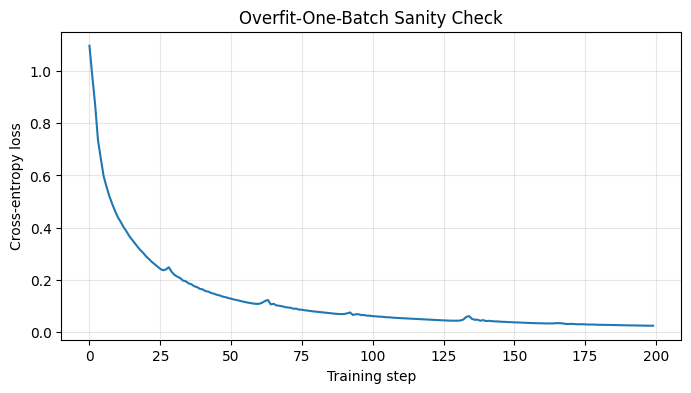

In [ ]:
# Plot overfit-one-batch loss

plt.figure(figsize=(8, 4))

plt.plot(sanity_losses)

plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Overfit-One-Batch Sanity Check")

plt.grid(alpha=0.3)
plt.show()

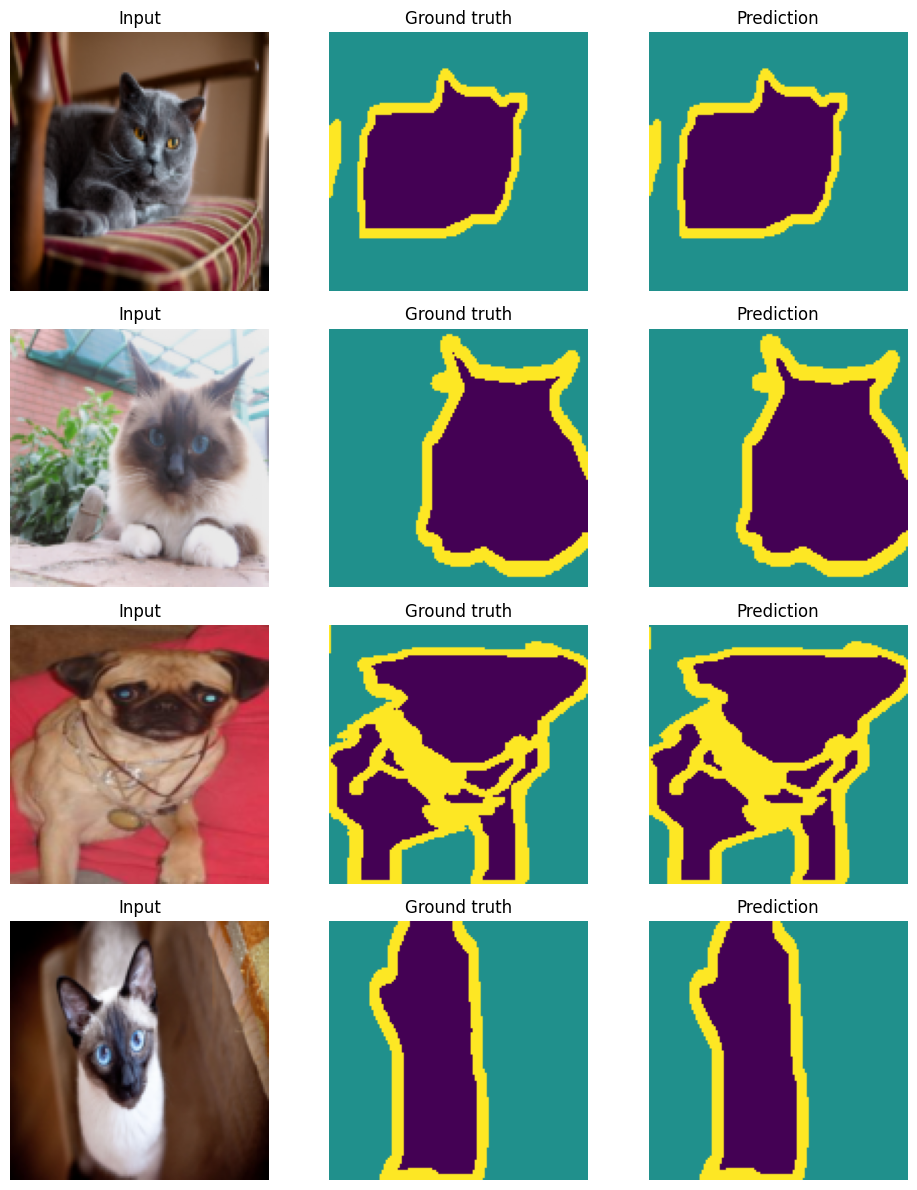

In [ ]:
# Visualize overfit-one-batch predictions

sanity_model.eval()

with torch.no_grad():

    predictions = sanity_model(
        small_images
    ).argmax(dim=1)

fig, axes = plt.subplots(
    SANITY_BATCH_SIZE,
    3,
    figsize=(10, 12)
)

for i in range(SANITY_BATCH_SIZE):

    axes[i, 0].imshow(
        denormalize(small_images[i])
    )

    axes[i, 0].set_title("Input")

    axes[i, 1].imshow(
        small_masks[i].cpu(),
        vmin=0,
        vmax=2,
        cmap="viridis"
    )

    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(
        predictions[i].cpu(),
        vmin=0,
        vmax=2,
        cmap="viridis"
    )

    axes[i, 2].set_title("Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Release GPU memory

del sanity_optimizer
del sanity_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
# Training

# Configure optimizer

ENCODER_LR = 1e-4
DECODER_LR = 1e-3

def make_optimizer(model):

    encoder_params = list(
        model.encoder.parameters()
    )

    decoder_params = [

        param

        for name, param in model.named_parameters()

        if not name.startswith("encoder.")

    ]

    optimizer = optim.Adam([

        {
            "params": encoder_params,
            "lr": ENCODER_LR
        },

        {
            "params": decoder_params,
            "lr": DECODER_LR
        }

    ])

    return optimizer

In [ ]:
# Training function

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion
):

    model.train()

    running_loss = 0.0
    total_images = 0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            masks
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        total_images += images.size(0)

    return running_loss / total_images

In [ ]:
# Validation function

@torch.no_grad()
def validate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0
    total_images = 0

    conf = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long,
        device=device
    )

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            masks
        )

        predictions = outputs.argmax(dim=1)

        conf += compute_confusion_matrix(
            predictions,
            masks,
            num_classes=NUM_CLASSES
        )

        running_loss += (
            loss.item() * images.size(0)
        )

        total_images += images.size(0)

    metrics = segmentation_metrics(conf)

    metrics["loss"] = (
        running_loss / total_images
    )

    return metrics

In [ ]:
# Full training loop

def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    epochs,
    checkpoint_path
):

    optimizer = make_optimizer(model)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_miou": [],
        "val_accuracy": [],
        "val_iou": [],
        "val_mdice": [],
        "epoch_time": []
    }

    best_miou = -float("inf")
    best_epoch = 0

    for epoch in range(epochs):

        start_time = time.time()

        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion
        )

        val_metrics = validate(
            model,
            val_loader,
            criterion
        )

        epoch_time = time.time() - start_time

        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_metrics["loss"]
        )

        history["val_miou"].append(
            val_metrics["miou"]
        )

        history["val_accuracy"].append(
            val_metrics["accuracy"]
        )

        history["val_iou"].append(
            val_metrics["iou"]
        )

        history["val_mdice"].append(
            val_metrics["mdice"]
        )

        history["epoch_time"].append(
            epoch_time
        )

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_metrics['loss']:.4f} | "
            f"Val mIoU: {val_metrics['miou']:.4f} | "
            f"Time: {epoch_time:.1f}s"
        )

        if val_metrics["miou"] > best_miou:

            best_miou = val_metrics["miou"]

            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            print("  Best model saved")

    # Restore the best validation checkpoint
    model.load_state_dict(

        torch.load(
            checkpoint_path,
            map_location=device
        )

    )

    print("\nTraining completed")

    print("Best epoch:", best_epoch)

    print(
        "Best validation mIoU:",
        f"{best_miou:.4f}"
    )

    return model, history, best_epoch

In [ ]:
# Train primary model

set_seed(SEED)

train_loader, val_loader = make_loaders(SEED)

model = ResNetUNet(
    num_classes=NUM_CLASSES
).to(device)

criterion = nn.CrossEntropyLoss()

model, history_ce, best_epoch_ce = fit_model(

    model=model,

    train_loader=train_loader,

    val_loader=val_loader,

    criterion=criterion,

    epochs=EPOCHS,

    checkpoint_path="best_resnet_unet_ce.pth"

)

Epoch 01/15 | Train loss: 0.4154 | Val loss: 0.2868 | Val mIoU: 0.7160 | Time: 19.3s
  Best model saved
Epoch 02/15 | Train loss: 0.2678 | Val loss: 0.2453 | Val mIoU: 0.7379 | Time: 18.1s
  Best model saved
Epoch 03/15 | Train loss: 0.2393 | Val loss: 0.2328 | Val mIoU: 0.7441 | Time: 19.5s
  Best model saved
Epoch 04/15 | Train loss: 0.2193 | Val loss: 0.2346 | Val mIoU: 0.7489 | Time: 18.5s
  Best model saved
Epoch 05/15 | Train loss: 0.2050 | Val loss: 0.2293 | Val mIoU: 0.7520 | Time: 19.4s
  Best model saved
Epoch 06/15 | Train loss: 0.1925 | Val loss: 0.2207 | Val mIoU: 0.7611 | Time: 18.5s
  Best model saved
Epoch 07/15 | Train loss: 0.1850 | Val loss: 0.2313 | Val mIoU: 0.7551 | Time: 18.6s
Epoch 08/15 | Train loss: 0.1775 | Val loss: 0.2169 | Val mIoU: 0.7660 | Time: 19.5s
  Best model saved
Epoch 09/15 | Train loss: 0.1694 | Val loss: 0.2287 | Val mIoU: 0.7569 | Time: 18.5s
Epoch 10/15 | Train loss: 0.1608 | Val loss: 0.2185 | Val mIoU: 0.7612 | Time: 19.9s
Epoch 11/15 | Tra

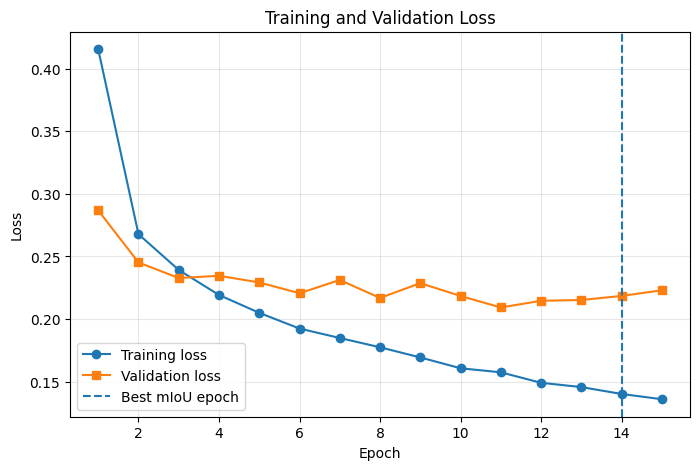

In [ ]:
# Training plots and results

# Loss curves

epoch_numbers = range(
    1,
    len(history_ce["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history_ce["train_loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    epoch_numbers,
    history_ce["val_loss"],
    marker="s",
    label="Validation loss"
)

plt.axvline(
    best_epoch_ce,
    linestyle="--",
    label="Best mIoU epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

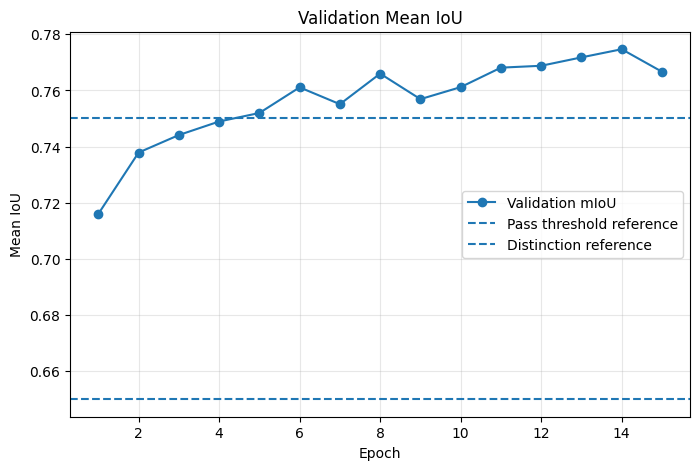

In [ ]:
# Validation mIoU

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    history_ce["val_miou"],
    marker="o",
    label="Validation mIoU"
)

plt.axhline(
    0.65,
    linestyle="--",
    label="Pass threshold reference"
)

plt.axhline(
    0.75,
    linestyle="--",
    label="Distinction reference"
)

plt.xlabel("Epoch")
plt.ylabel("Mean IoU")
plt.title("Validation Mean IoU")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

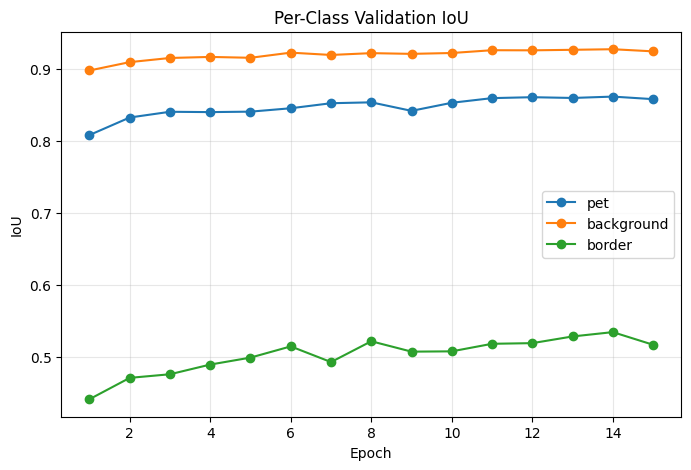

In [ ]:
# Per-class validation IoU

val_ious = np.array(
    history_ce["val_iou"]
)

plt.figure(figsize=(8, 5))

for i, name in enumerate(CLASS_NAMES):

    plt.plot(
        epoch_numbers,
        val_ious[:, i],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("Per-Class Validation IoU")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Question Sheet Section G results

best_idx = best_epoch_ce - 1

print("=" * 55)
print("SECTION G - TRAINING RESULTS")
print("=" * 55)

print("G1. Loss: CrossEntropyLoss")
print("G1. Optimizer: Adam")
print("G1. Encoder LR:", ENCODER_LR)
print("G1. Decoder LR:", DECODER_LR)
print("G1. Epochs:", EPOCHS)

print(
    "G2. Average seconds per epoch:",
    f"{np.mean(history_ce['epoch_time']):.2f}"
)

print("G3. Best epoch:", best_epoch_ce)

print(
    "G3. Training loss:",
    f"{history_ce['train_loss'][best_idx]:.4f}"
)

print(
    "G3. Validation loss:",
    f"{history_ce['val_loss'][best_idx]:.4f}"
)

print(
    "G3. Validation mean IoU:",
    f"{history_ce['val_miou'][best_idx]:.4f}"
)

SECTION G - TRAINING RESULTS
G1. Loss: CrossEntropyLoss
G1. Optimizer: Adam
G1. Encoder LR: 0.0001
G1. Decoder LR: 0.001
G1. Epochs: 15
G2. Average seconds per epoch: 18.94
G3. Best epoch: 14
G3. Training loss: 0.1403
G3. Validation loss: 0.2185
G3. Validation mean IoU: 0.7747


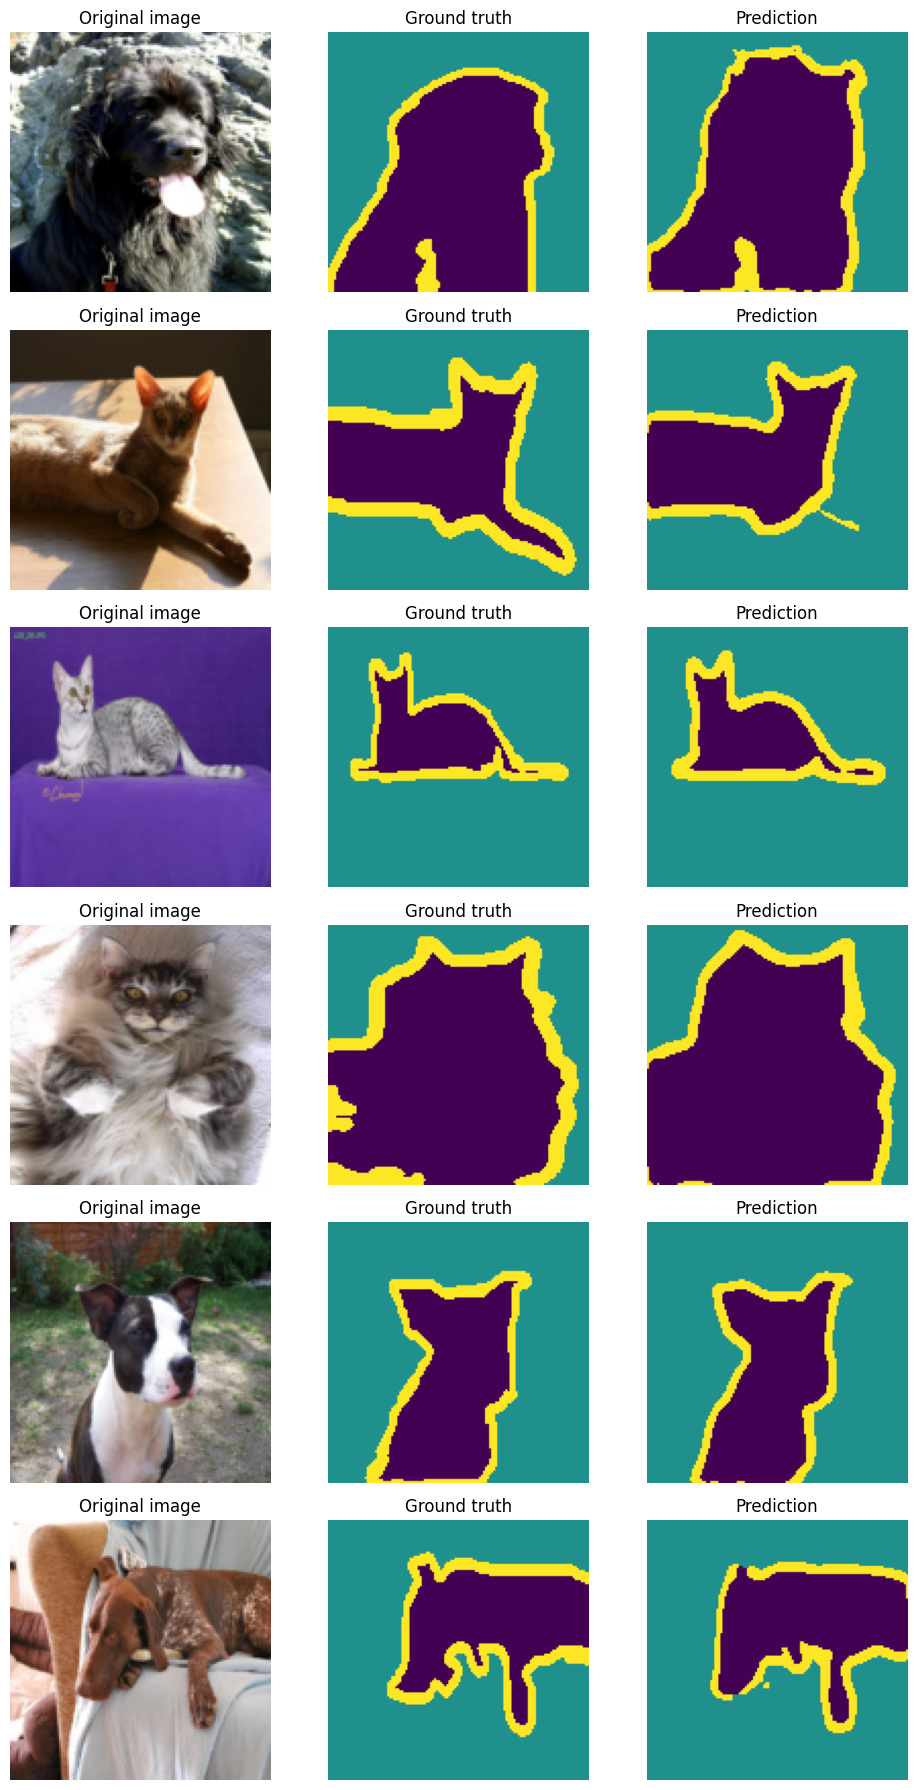

In [ ]:
# Visualize validation predictions

def show_predictions(model, loader, n=6):

    model.eval()

    images, masks = next(iter(loader))

    with torch.no_grad():

        predictions = model(

            images.to(device)

        ).argmax(dim=1).cpu()

    n = min(n, len(images))

    fig, axes = plt.subplots(
        n,
        3,
        figsize=(10, 3 * n)
    )

    for i in range(n):

        axes[i, 0].imshow(
            denormalize(images[i])
        )

        axes[i, 0].set_title("Original image")

        axes[i, 1].imshow(
            masks[i],
            cmap="viridis",
            vmin=0,
            vmax=2
        )

        axes[i, 1].set_title("Ground truth")

        axes[i, 2].imshow(
            predictions[i],
            cmap="viridis",
            vmin=0,
            vmax=2
        )

        axes[i, 2].set_title("Prediction")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(model, val_loader)

In [ ]:
# One-variable experiment

# Implement Dice loss

class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):

        super().__init__()

        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        targets_onehot = F.one_hot(
            targets,
            num_classes=logits.shape[1]
        )

        targets_onehot = (

            targets_onehot
            .permute(0, 3, 1, 2)
            .float()

        )

        dims = (0, 2, 3)

        intersection = (

            probabilities * targets_onehot

        ).sum(dim=dims)

        denominator = (

            probabilities.sum(dim=dims)

            + targets_onehot.sum(dim=dims)

        )

        dice = (

            2 * intersection + self.smooth

        ) / (

            denominator + self.smooth

        )

        return 1 - dice.mean()

In [ ]:
# Combined loss

class CombinedLoss(nn.Module):

    def __init__(self):

        super().__init__()

        self.ce = nn.CrossEntropyLoss()

        self.dice = DiceLoss()

    def forward(self, logits, targets):

        ce_loss = self.ce(
            logits,
            targets
        )

        dice_loss = self.dice(
            logits,
            targets
        )

        return ce_loss + dice_loss

In [ ]:
# Train experiment model

set_seed(SEED)

# Recreate loaders to use the same seed
train_loader_exp, val_loader_exp = make_loaders(SEED)

# Start from the same initialization
experiment_model = ResNetUNet(
    num_classes=NUM_CLASSES
).to(device)

experiment_criterion = CombinedLoss()

experiment_model, history_dice, best_epoch_dice = fit_model(

    model=experiment_model,

    train_loader=train_loader_exp,

    val_loader=val_loader_exp,

    criterion=experiment_criterion,

    epochs=EPOCHS,

    checkpoint_path="best_resnet_unet_dice.pth"

)

Epoch 01/15 | Train loss: 0.7268 | Val loss: 0.5157 | Val mIoU: 0.7204 | Time: 18.9s
  Best model saved
Epoch 02/15 | Train loss: 0.4897 | Val loss: 0.4570 | Val mIoU: 0.7409 | Time: 19.4s
  Best model saved
Epoch 03/15 | Train loss: 0.4397 | Val loss: 0.4345 | Val mIoU: 0.7517 | Time: 18.6s
  Best model saved
Epoch 04/15 | Train loss: 0.4057 | Val loss: 0.4313 | Val mIoU: 0.7556 | Time: 19.6s
  Best model saved
Epoch 05/15 | Train loss: 0.3789 | Val loss: 0.4391 | Val mIoU: 0.7538 | Time: 18.5s
Epoch 06/15 | Train loss: 0.3638 | Val loss: 0.4135 | Val mIoU: 0.7598 | Time: 19.9s
  Best model saved
Epoch 07/15 | Train loss: 0.3537 | Val loss: 0.4368 | Val mIoU: 0.7556 | Time: 19.0s
Epoch 08/15 | Train loss: 0.3304 | Val loss: 0.3973 | Val mIoU: 0.7703 | Time: 19.5s
  Best model saved
Epoch 09/15 | Train loss: 0.3160 | Val loss: 0.3892 | Val mIoU: 0.7736 | Time: 19.0s
  Best model saved
Epoch 10/15 | Train loss: 0.3093 | Val loss: 0.4070 | Val mIoU: 0.7690 | Time: 18.8s
Epoch 11/15 | Tra

In [ ]:
# Compare both experiments

best_ce_miou = max(
    history_ce["val_miou"]
)

best_dice_miou = max(
    history_dice["val_miou"]
)

miou_change = (
    best_dice_miou - best_ce_miou
)

print("=" * 55)
print("CONTROLLED EXPERIMENT RESULTS")
print("=" * 55)

print(
    "Best CE validation mIoU:",
    f"{best_ce_miou:.4f}"
)

print(
    "Best CE + Dice validation mIoU:",
    f"{best_dice_miou:.4f}"
)

print(
    "I3. Actual change:",
    f"{miou_change:+.4f}"
)

print(
    "Change in percentage points:",
    f"{miou_change * 100:+.2f}"
)

CONTROLLED EXPERIMENT RESULTS
Best CE validation mIoU: 0.7747
Best CE + Dice validation mIoU: 0.7780
I3. Actual change: +0.0034
Change in percentage points: +0.34


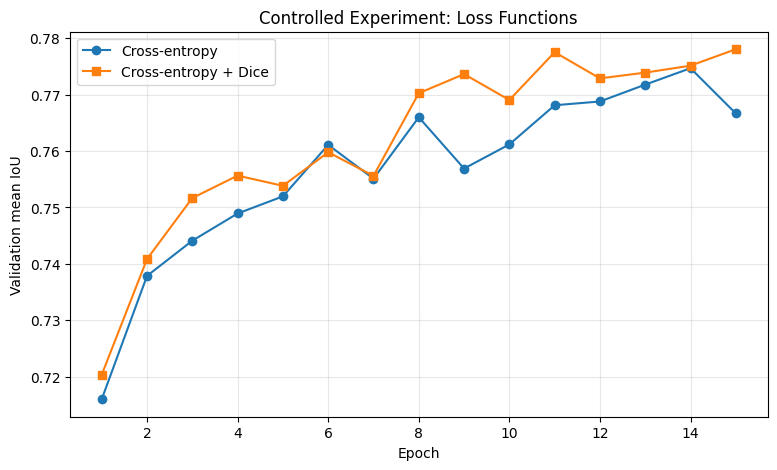

In [ ]:
# Comparison plot

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),

    history_ce["val_miou"],

    marker="o",

    label="Cross-entropy"
)

plt.plot(
    range(1, EPOCHS + 1),

    history_dice["val_miou"],

    marker="s",

    label="Cross-entropy + Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Validation mean IoU")

plt.title("Controlled Experiment: Loss Functions")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Compare per-class IoU

ce_ious = history_ce["val_iou"][
    best_epoch_ce - 1
]

dice_ious = history_dice["val_iou"][
    best_epoch_dice - 1
]

print(
    f"{'Class':12s}"
    f"{'CE':>12s}"
    f"{'CE+Dice':>12s}"
    f"{'Change':>12s}"
)

for i, name in enumerate(CLASS_NAMES):

    print(
        f"{name:12s}"
        f"{ce_ious[i]:12.4f}"
        f"{dice_ious[i]:12.4f}"
        f"{dice_ious[i] - ce_ious[i]:+12.4f}"
    )

Class                 CE     CE+Dice      Change
pet               0.8617      0.8626     +0.0009
background        0.9275      0.9274     -0.0001
border            0.5348      0.5441     +0.0093


In [ ]:
# Select the best model using validation mIoU

if best_dice_miou > best_ce_miou:

    model = experiment_model

    final_history = history_dice
    final_best_epoch = best_epoch_dice

    selected_loss = "CrossEntropy + Dice"

else:

    final_history = history_ce
    final_best_epoch = best_epoch_ce

    selected_loss = "CrossEntropyLoss"

model = model.to(device)

model.eval()

print("Selected model:", selected_loss)

print(
    "Best validation mIoU:",
    f"{max(final_history['val_miou']):.4f}"
)

print("Best validation epoch:", final_best_epoch)

Selected model: CrossEntropy + Dice
Best validation mIoU: 0.7780
Best validation epoch: 15


In [ ]:
# Final selected model's training details

final_idx = final_best_epoch - 1

print("Final loss:", selected_loss)
print("Optimizer: Adam")

print("Epochs:", EPOCHS)

print(
    "Average seconds per epoch:",
    f"{np.mean(final_history['epoch_time']):.2f}"
)

print("Best epoch:", final_best_epoch)

print(
    "Train loss:",
    f"{final_history['train_loss'][final_idx]:.4f}"
)

print(
    "Validation loss:",
    f"{final_history['val_loss'][final_idx]:.4f}"
)

print(
    "Validation mIoU:",
    f"{final_history['val_miou'][final_idx]:.4f}"
)

torch.save(
    model.state_dict(),
    "final_segmentation_model.pth"
)

Final loss: CrossEntropy + Dice
Optimizer: Adam
Epochs: 15
Average seconds per epoch: 19.21
Best epoch: 15
Train loss: 0.2711
Validation loss: 0.3916
Validation mIoU: 0.7780


Loading the hidden test set (first call only, takes a minute)...
OFFICIAL RESULT on 3669 test images   (6s)
                  your model    all-background
pixel accuracy        0.9219            0.5772
mean IoU              0.7822            0.1924
mean Dice             0.8682
  IoU pet             0.8593
  IoU background      0.9273
  IoU border          0.5599
  Dice pet            0.9243
  Dice background     0.9623
  Dice border         0.7178
------------------------------------------------------------
Shape check : PASSED
Beats the all-background baseline : PASSED
mIoU >= 0.65 : PASSED
VERDICT: PASS  (DISTINCTION!)


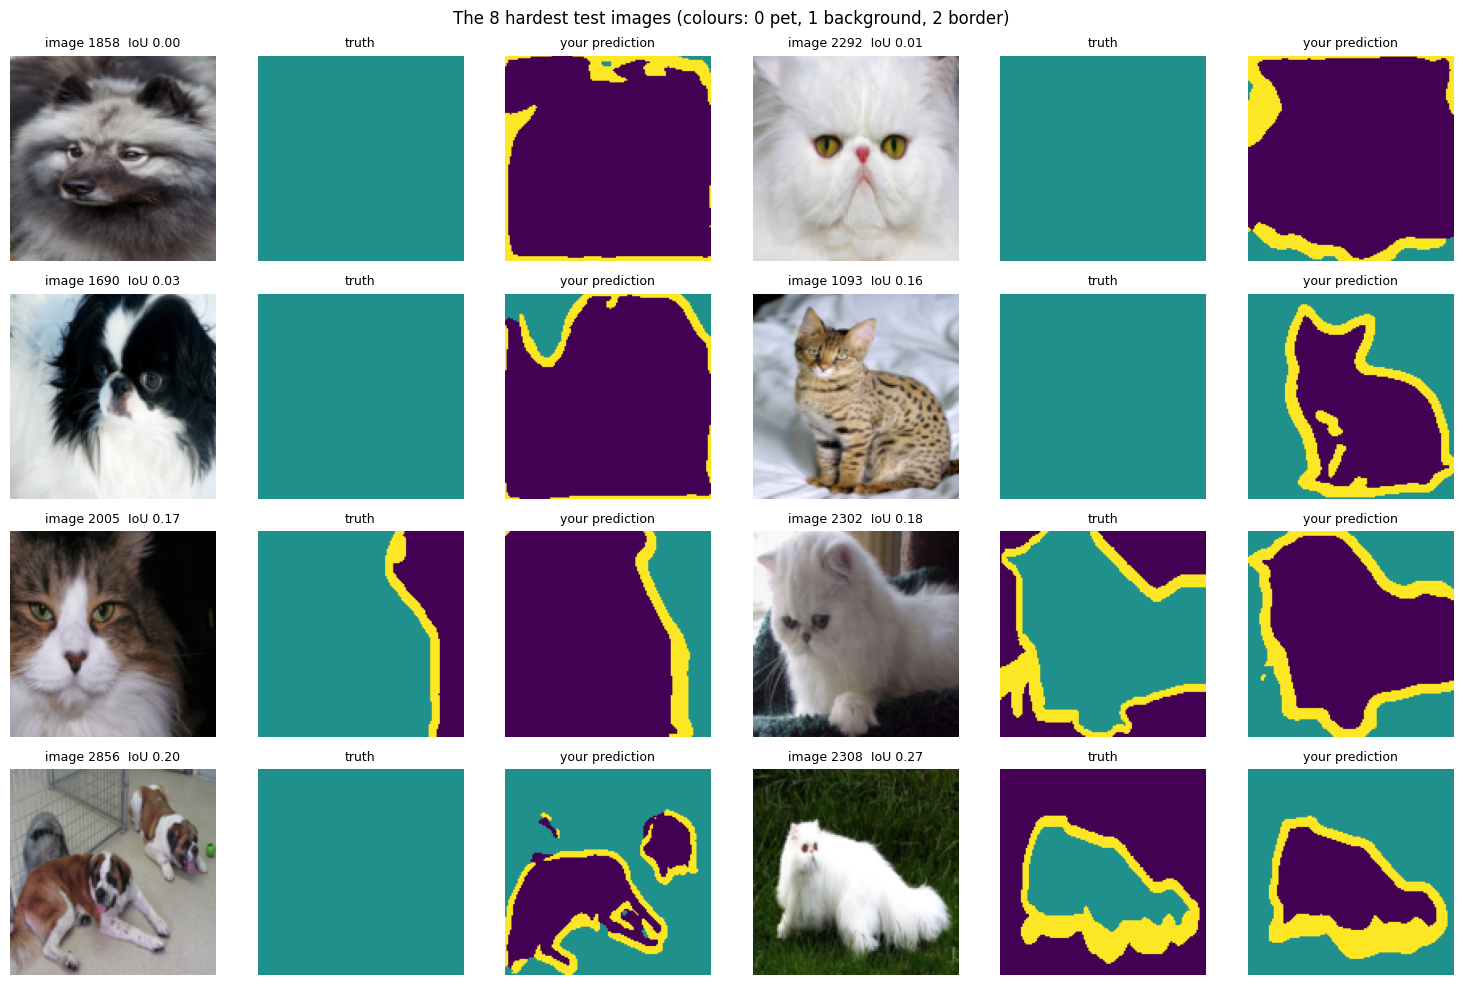

In [ ]:
# Official final evaluation

results = evaluate(model)

In [ ]:
# Additional cell after the checker — Extract Question Sheet answers

print("=" * 55)
print("FINAL QUESTION SHEET ANSWERS")
print("=" * 55)

print(
    "C5. Baseline accuracy:",
    f"{3 * results['baseline_miou']:.4f}"
)

print(
    "C5. Baseline mIoU:",
    f"{results['baseline_miou']:.4f}"
)

print(
    "H1. Test mean IoU:",
    f"{results['miou']:.4f}"
)

print(
    "H2. Pet IoU:",
    f"{results['iou']['pet']:.4f}"
)

print(
    "H2. Background IoU:",
    f"{results['iou']['background']:.4f}"
)

print(
    "H2. Border IoU:",
    f"{results['iou']['border']:.4f}"
)

lowest_class = min(
    results["iou"],
    key=results["iou"].get
)

print("H3. Lowest IoU class:", lowest_class)

print("Passed:", results["passed"])

FINAL QUESTION SHEET ANSWERS
C5. Baseline accuracy: 0.5772
C5. Baseline mIoU: 0.1924
H1. Test mean IoU: 0.7822
H2. Pet IoU: 0.8593
H2. Background IoU: 0.9273
H2. Border IoU: 0.5599
H3. Lowest IoU class: border
Passed: True


---
## **FINAL EVALUATION**
Run this when your model is ready. You can run it several times, but make your *decisions* (epochs, settings, which experiment is better) using your validation split, not by repeatedly peeking at this score. Keep the output visible when you submit.

OFFICIAL RESULT on 3669 test images   (5s)
                  your model    all-background
pixel accuracy        0.9219            0.5772
mean IoU              0.7822            0.1924
mean Dice             0.8682
  IoU pet             0.8593
  IoU background      0.9273
  IoU border          0.5599
  Dice pet            0.9243
  Dice background     0.9623
  Dice border         0.7178
------------------------------------------------------------
Shape check : PASSED
Beats the all-background baseline : PASSED
mIoU >= 0.65 : PASSED
VERDICT: PASS  (DISTINCTION!)


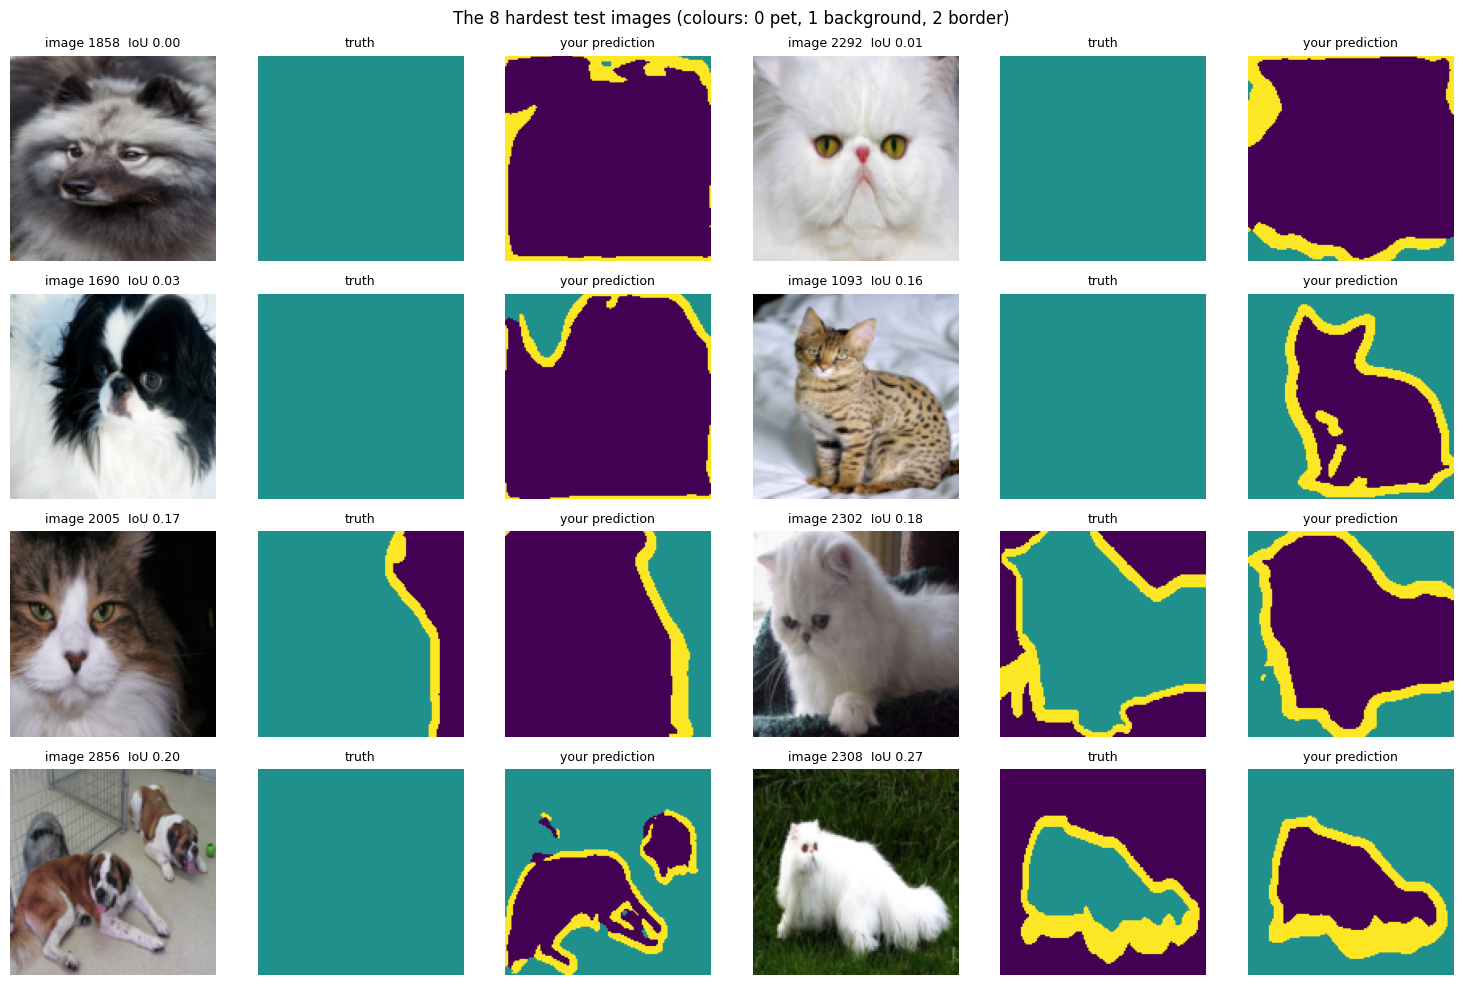

In [ ]:
# ===================== DO NOT EDIT THIS CELL =====================
# Your trained network must be in a variable called `model` (already on the GPU, if you trained on the GPU).
results = evaluate(model)

---
## **WRITTEN NOTES**  (replace the `____`; a few sentences each, refer to your own plots and numbers)

**Experiment (Section I):** What did you change, what did you predict and why, what happened, and why do you think it happened?

____

**Failure analysis:** Look at the 8 hardest test images from the checker. What do they have in common (thin legs or tails, fur colour like the background, several animals, cropped pet, border pixels)? What would you try next?

____

**Why is the border class the hardest?** (Use your IoU numbers and the images.)

____